# 05_Sales Performance

## 1. Objectifs de l'analyse

Ce notebook approfondit la performance commerciale d'AdventureWorks sur la période couverte par les ventes.

L'analyse porte sur trois dimensions :
- l'évolution temporelle du chiffre d'affaires, des commandes et des quantités ;
- la rentabilité estimée des ventes ;
- la performance commerciale selon les territoires, les pays et les groupes géographiques.

Les coûts et bénéfices calculés à partir de `CalculatedTotalCost` restent des estimations fondées sur les coûts standards.

In [101]:
# Importer les bibliothèques nécessaires
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Définir le chemin du projet
BASE_DIR = Path.cwd().parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"

# Charger les cinq tables préparées
dim_date = pd.read_csv(
    PROCESSED_DIR / "DimDate.csv",
    parse_dates=["Date"]
)

dim_customer = pd.read_csv(
    PROCESSED_DIR / "DimCustomer.csv",
    parse_dates=["BirthDate", "DateFirstPurchase"]
)

dim_product = pd.read_csv(
    PROCESSED_DIR / "DimProduct.csv",
    parse_dates=["StartDate"]
)

fact_sales = pd.read_csv(
    PROCESSED_DIR / "FactInternetSales.csv",
    parse_dates=["OrderDate", "ShipDate"]
)

dim_territory = pd.read_csv(
    PROCESSED_DIR / "DimSalesTerritory.csv"
)

print("Chargement des données préparées terminé.")

Chargement des données préparées terminé.


## 2. Analyse temporelle des ventes

In [103]:
# Vérifier l'unicité des lignes de commande
doublons_lignes = fact_sales.duplicated(
    subset=["SalesOrderNumber", "SalesOrderLineNumber"]
).sum()

print("Nombre de lignes de commande en doublon :", doublons_lignes)

# Vérifier les identifiants manquants
print("\nValeurs manquantes :")
display(
    fact_sales[
        ["SalesOrderNumber", "SalesOrderLineNumber"]
    ].isna().sum()
)

Nombre de lignes de commande en doublon : 0

Valeurs manquantes :


SalesOrderNumber        0
SalesOrderLineNumber    0
dtype: int64

In [104]:
# Créer une colonne correspondant au mois de commande
fact_sales["Month"] = (
    fact_sales["OrderDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Regrouper les ventes par mois
ventes_mensuelles = (
    fact_sales
    .groupby("Month")
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Quantite_Vendue=("OrderQuantity", "sum")
    )
    .reset_index()
)

# Afficher les premières lignes
ventes_mensuelles.head(10)

,Month,Chiffre_Affaires,Nombre_Commandes,Quantite_Vendue
0,2014-01-01,473388.1630,146,246
1,2014-02-01,506191.6912,156,246
2,2014-03-01,473943.0312,146,227
3,2014-04-01,513329.4740,161,269
4,2014-05-01,543993.4058,169,265
5,2014-06-01,755527.8914,235,354
6,2014-07-01,596746.5568,188,286
7,2014-08-01,550816.6940,171,279
8,2014-09-01,644135.2022,199,316
9,2014-10-01,663692.2868,207,339


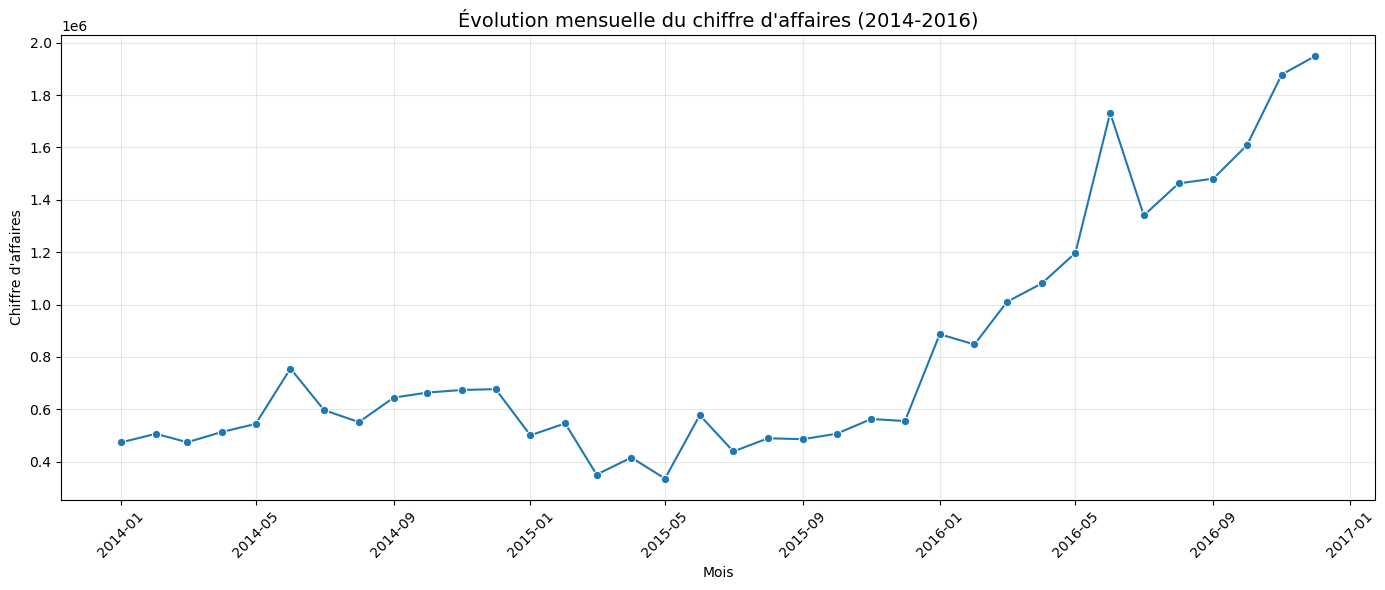

In [105]:
# Définir la taille du graphique
plt.figure(figsize=(14, 6))

# Tracer l'évolution mensuelle du chiffre d'affaires
sns.lineplot(
    data=ventes_mensuelles,
    x="Month",
    y="Chiffre_Affaires",
    marker="o"
)

# Personnaliser le graphique
plt.title(
    "Évolution mensuelle du chiffre d'affaires (2014-2016)",
    fontsize=14
)
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [106]:
# Ajouter l'année à partir de la date mensuelle
ventes_mensuelles["Annee"] = ventes_mensuelles["Month"].dt.year

# Regrouper les indicateurs par année
ventes_annuelles = (
    ventes_mensuelles
    .groupby("Annee")
    .agg(
        Chiffre_Affaires=("Chiffre_Affaires", "sum"),
        Nombre_Commandes=("Nombre_Commandes", "sum"),
        Quantite_Vendue=("Quantite_Vendue", "sum")
    )
    .reset_index()
)

# Calculer l'évolution annuelle du chiffre d'affaires
ventes_annuelles["Evolution_CA_%"] = (
    ventes_annuelles["Chiffre_Affaires"]
    .pct_change() * 100
)

ventes_annuelles

,Annee,Chiffre_Affaires,Nombre_Commandes,Quantite_Vendue,Evolution_CA_%
0,2014,7.072084e+06,2206,3492,NaN
1,2015,5.762134e+06,3222,4945,-18.522827
2,2016,1.647362e+07,21255,82884,185.894379


In [107]:
# Identifier les cinq mois ayant le chiffre d'affaires le plus élevé
meilleurs_mois = (
    ventes_mensuelles
    .nlargest(5, "Chiffre_Affaires")
)

# Identifier les cinq mois ayant le chiffre d'affaires le plus faible
mois_faibles = (
    ventes_mensuelles
    .nsmallest(5, "Chiffre_Affaires")
)

print("TOP 5 DES MOIS")
display(meilleurs_mois)

print("FLOP 5 DES MOIS")
display(mois_faibles)

TOP 5 DES MOIS


,Month,Chiffre_Affaires,Nombre_Commandes,Quantite_Vendue,Annee
35,2016-12-01,1949361.11,2195,9065,2016
34,2016-11-01,1878317.51,2206,8969,2016
29,2016-06-01,1731787.77,2096,8465,2016
33,2016-10-01,1608750.53,2035,7727,2016
32,2016-09-01,1480905.18,1933,7553,2016


FLOP 5 DES MOIS


,Month,Chiffre_Affaires,Nombre_Commandes,Quantite_Vendue,Annee
16,2015-05-01,335095.0887,193,303,2015
14,2015-03-01,350466.9912,198,336,2015
15,2015-04-01,415390.2333,229,348,2015
18,2015-07-01,438865.1718,244,345,2015
0,2014-01-01,473388.1630,146,246,2014


In [108]:
# Ajouter l'année directement à la table des ventes
fact_sales["Annee"] = fact_sales["OrderDate"].dt.year

# Comparer les principaux indicateurs par année
comparaison_annuelle = (
    fact_sales
    .groupby("Annee")
    .agg(
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Nombre_Clients=("CustomerKey", "nunique"),
        Quantite_Vendue=("OrderQuantity", "sum"),
        Chiffre_Affaires=("SalesAmount", "sum")
    )
    .reset_index()
)

# Calculer le chiffre d'affaires moyen par commande
comparaison_annuelle["CA_Moyen_Commande"] = (
    comparaison_annuelle["Chiffre_Affaires"]
    / comparaison_annuelle["Nombre_Commandes"]
)

# Calculer la quantité moyenne par commande
comparaison_annuelle["Quantite_Moyenne_Commande"] = (
    comparaison_annuelle["Quantite_Vendue"]
    / comparaison_annuelle["Nombre_Commandes"]
)

comparaison_annuelle

,Annee,Nombre_Lignes,Nombre_Commandes,Nombre_Clients,Quantite_Vendue,Chiffre_Affaires,CA_Moyen_Commande,Quantite_Moyenne_Commande
0,2014,2206,2206,2206,3492,7.072084e+06,3205.840546,1.582956
1,2015,3222,3222,3222,4945,5.762134e+06,1788.371911,1.534761
2,2016,52761,21255,17412,82884,1.647362e+07,775.046721,3.899506


In [109]:
# Examiner le volume de lignes de vente par mois et par année
repartition_mensuelle = (
    fact_sales
    .groupby([
        fact_sales["OrderDate"].dt.year.rename("Annee"),
        fact_sales["OrderDate"].dt.month.rename("Mois")
    ])
    .agg(
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Chiffre_Affaires=("SalesAmount", "sum")
    )
    .reset_index()
)

# Comparer le nombre de lignes par mois selon les années
repartition_mensuelle.pivot(
    index="Mois",
    columns="Annee",
    values="Nombre_Lignes"
)

Annee,2014,2015,2016
Mois,,,
1,146,253,1411
2,156,281,3819
3,146,198,3885
4,161,229,4146
5,169,193,4174
6,235,330,5270
7,188,244,4585
8,171,272,4616
9,199,272,4707


In [110]:
# Examiner la période couverte par les ventes
print("Période des commandes :")
print("Première date :", fact_sales["OrderDate"].min())
print("Dernière date :", fact_sales["OrderDate"].max())

print("\nNombre de commandes par année :")
print(
    fact_sales.groupby(
        fact_sales["OrderDate"].dt.year
    )["SalesOrderNumber"].nunique()
)

# Examiner la couverture de la dimension temporelle
print("\nPériode de la dimension DimDate :")
print("Première date :", dim_date["Date"].min())
print("Dernière date :", dim_date["Date"].max())

print("\nNombre de dates par année dans DimDate :")
print(
    dim_date.groupby(
        dim_date["Date"].dt.year
    )["Date"].count()
)

Période des commandes :
Première date : 2014-01-01 00:00:00
Dernière date : 2016-12-30 00:00:00

Nombre de commandes par année :
OrderDate
2014     2206
2015     3222
2016    21255
Name: SalesOrderNumber, dtype: int64

Période de la dimension DimDate :
Première date : 2014-01-01 00:00:00
Dernière date : 2017-12-31 00:00:00

Nombre de dates par année dans DimDate :
Date
2014    365
2015    365
2016    366
2017    365
Name: Date, dtype: int64


In [111]:
# Compter les commandes distinctes par date
commandes_par_date = (
    fact_sales
    .groupby("OrderDate")["SalesOrderNumber"]
    .nunique()
)

# Examiner la distribution des commandes quotidiennes
commandes_par_date.describe()

count    1073.000000
mean       24.867661
std        26.897491
min         1.000000
25%         6.000000
50%        10.000000
75%        52.000000
max       161.000000
Name: SalesOrderNumber, dtype: float64

In [112]:
# Regrouper les données au niveau de la commande
commandes = (
    fact_sales
    .groupby(["SalesOrderNumber", "Annee"])
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Quantite_Totale=("OrderQuantity", "sum")
    )
    .reset_index()
)

# Calculer les indicateurs annuels au niveau des commandes
analyse_panier = (
    commandes
    .groupby("Annee")
    .agg(
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        CA_Moyen_Commande=("Chiffre_Affaires", "mean"),
        Lignes_Moyennes_Commande=("Nombre_Lignes", "mean"),
        Quantite_Moyenne_Commande=("Quantite_Totale", "mean"),
        CA_Median_Commande=("Chiffre_Affaires", "median")
    )
    .reset_index()
)

analyse_panier

,Annee,Nombre_Commandes,CA_Moyen_Commande,Lignes_Moyennes_Commande,Quantite_Moyenne_Commande,CA_Median_Commande
0,2014,2206,3205.840546,1.000000,1.582956,3578.2700
1,2015,3222,1788.371911,1.000000,1.534761,2071.4196
2,2016,21255,775.046721,2.482287,3.899506,115.9500


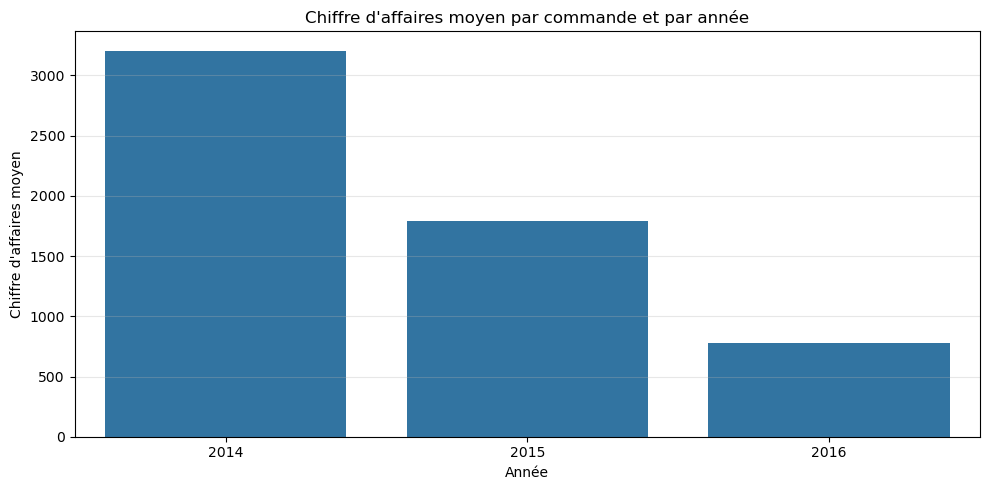

In [113]:
# Préparer les données pour la visualisation
plt.figure(figsize=(10, 5))

sns.barplot(
    data=analyse_panier,
    x="Annee",
    y="CA_Moyen_Commande"
)

plt.title("Chiffre d'affaires moyen par commande et par année")
plt.xlabel("Année")
plt.ylabel("Chiffre d'affaires moyen")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [114]:
# Calculer les statistiques descriptives des montants par commande
statistiques_commandes = (
    commandes
    .groupby("Annee")["Chiffre_Affaires"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

statistiques_commandes

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Annee,,,,,,,,,,,
2014,2206.0,3205.840546,917.364107,699.0982,3399.9900,3578.2700,3578.2700,3578.27,3578.27,3578.27,3578.27
2015,3222.0,1788.371911,611.885761,782.9900,1000.4375,2071.4196,2181.5625,2443.35,2443.35,2443.35,2443.35
2016,21255.0,775.046721,942.205341,2.2900,38.9800,115.9500,1700.9900,2393.06,2438.06,2493.54,2641.23


In [115]:
# Extraire les commandes de 2016
commandes_2016 = commandes[
    commandes["Annee"] == 2016
].copy()

# Identifier les dix commandes ayant le chiffre d'affaires le plus élevé
top_commandes_2016 = (
    commandes_2016
    .nlargest(10, "Chiffre_Affaires")
)

top_commandes_2016

,SalesOrderNumber,Annee,Chiffre_Affaires,Nombre_Lignes,Quantite_Totale
8491,SO54601,2016,2641.23,5,5
5431,SO51179,2016,2638.94,4,4
9818,SO56027,2016,2638.94,4,16
11350,SO57738,2016,2638.94,4,16
21793,SO68897,2016,2638.94,4,4
24284,SO71568,2016,2638.94,4,4
5740,SO51488,2016,2618.62,5,10
5928,SO51676,2016,2595.95,3,3
24220,SO71504,2016,2589.41,6,6
17757,SO64592,2016,2588.33,6,6


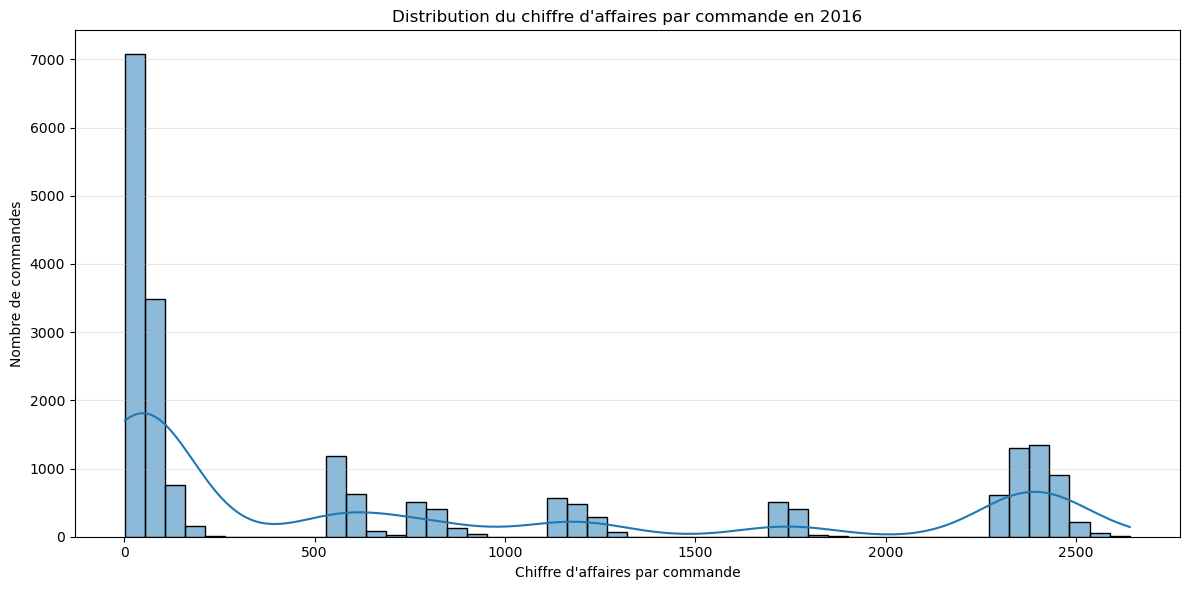

In [116]:
# Représenter la distribution des montants des commandes
plt.figure(figsize=(12, 6))

sns.histplot(
    data=commandes_2016,
    x="Chiffre_Affaires",
    bins=50,
    kde=True
)

plt.title("Distribution du chiffre d'affaires par commande en 2016")
plt.xlabel("Chiffre d'affaires par commande")
plt.ylabel("Nombre de commandes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [117]:
# Définir les tranches de chiffre d'affaires
bornes = [0, 100, 500, 1000, 2000, 3000, float("inf")]

etiquettes = [
    "0 à 100",
    "100 à 500",
    "500 à 1 000",
    "1 000 à 2 000",
    "2 000 à 3 000",
    "Plus de 3 000"
]

# Classer les commandes dans les différentes tranches
commandes_2016["Tranche_CA"] = pd.cut(
    commandes_2016["Chiffre_Affaires"],
    bins=bornes,
    labels=etiquettes,
    include_lowest=True,
    right=True
)

# Vérifier que toutes les commandes ont été classées
print(
    "Commandes non classées :",
    commandes_2016["Tranche_CA"].isna().sum()
)

# Calculer le nombre et la proportion de commandes par tranche
repartition_commandes = (
    commandes_2016
    .groupby("Tranche_CA", observed=False)
    .agg(
        Nombre_Commandes=("SalesOrderNumber", "count"),
        Chiffre_Affaires=("Chiffre_Affaires", "sum")
    )
    .reset_index()
)

repartition_commandes["Part_Commandes_%"] = (
    repartition_commandes["Nombre_Commandes"]
    / len(commandes_2016) * 100
)

repartition_commandes["Part_CA_%"] = (
    repartition_commandes["Chiffre_Affaires"]
    / commandes_2016["Chiffre_Affaires"].sum() * 100
)

repartition_commandes

Commandes non classées : 0


,Tranche_CA,Nombre_Commandes,Chiffre_Affaires,Part_Commandes_%,Part_CA_%
0,0 à 100,10452,442749.95,49.174312,2.687630
1,100 à 500,1026,138904.56,4.827100,0.843194
2,500 à 1 000,3005,1985172.12,14.137850,12.050614
3,1 000 à 2 000,2334,3284198.84,10.980946,19.936111
4,2 000 à 3 000,4438,10622592.58,20.879793,64.482450
5,Plus de 3 000,0,0.00,0.000000,0.000000


In [118]:
# Calculer les quartiles et la moyenne par année
profil_commandes = (
    commandes
    .groupby("Annee")["Chiffre_Affaires"]
    .agg(
        Moyenne="mean",
        Mediane="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

profil_commandes

,Annee,Moyenne,Mediane,Q1,Q3,Minimum,Maximum
0,2014,3205.840546,3578.2700,3399.9900,3578.2700,699.0982,3578.27
1,2015,1788.371911,2071.4196,1000.4375,2181.5625,782.9900,2443.35
2,2016,775.046721,115.9500,38.9800,1700.9900,2.2900,2641.23


### Synthèse de l'analyse temporelle

L'analyse de la période 2014-2016 révèle une forte progression du chiffre d'affaires en 2016, accompagnée d'une augmentation importante du nombre de commandes et des quantités vendues.

Cependant, cette progression s'accompagne d'une modification notable de la structure des commandes. En 2016, les commandes présentent une forte concentration dans les montants les plus faibles. Les commandes comprises entre 0 et 100 représentent 49,17 % du volume total, mais ne contribuent qu'à hauteur de 2,69 % du chiffre d'affaires.

À l'inverse, les commandes comprises entre 2 000 et 3 000 représentent 20,88 % du volume et génèrent 64,48 % du chiffre d'affaires. Cette tranche constitue le principal contributeur au chiffre d'affaires.

Cette répartition met en évidence une contribution très inégale des commandes à l'activité commerciale. Elle ne permet toutefois pas, à elle seule, d'expliquer les raisons de ces différences.

## 3. Analyse de la rentabilité

In [121]:
# Regrouper les ventes par année
rentabilite_annuelle = (
    fact_sales
    .groupby(fact_sales["OrderDate"].dt.year.rename("Annee"))
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Cout_Total_Estime=("CalculatedTotalCost", "sum"),
        Nombre_Lignes=("SalesOrderNumber", "count")
    )
    .reset_index()
)

# Calculer le bénéfice brut estimé
rentabilite_annuelle["Benefice_Brut_Estime"] = (
    rentabilite_annuelle["Chiffre_Affaires"]
    - rentabilite_annuelle["Cout_Total_Estime"]
)

# Calculer les taux de marge et de marque avec leurs dénominateurs respectifs
rentabilite_annuelle["Taux_Marge_Estime_%"] = (
    rentabilite_annuelle["Benefice_Brut_Estime"]
    / rentabilite_annuelle["Cout_Total_Estime"] * 100
)

rentabilite_annuelle["Taux_Marque_Estime_%"] = (
    rentabilite_annuelle["Benefice_Brut_Estime"]
    / rentabilite_annuelle["Chiffre_Affaires"] * 100
)

display(rentabilite_annuelle.round(2))

,Annee,Chiffre_Affaires,Cout_Total_Estime,Nombre_Lignes,Benefice_Brut_Estime,Taux_Marge_Estime_%,Taux_Marque_Estime_%
0,2014,7072084.24,6635822.93,2206,436261.31,6.57,6.17
1,2015,5762134.30,5200982.35,3222,561151.94,10.79,9.74
2,2016,16473618.05,15236675.33,52761,1236942.72,8.12,7.51


In [122]:
# Regrouper les ventes par mois
rentabilite_mensuelle = (
    fact_sales
    .groupby("Month")
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Cout_Total_Estime=("CalculatedTotalCost", "sum")
    )
    .reset_index()
)

# Calculer le bénéfice brut estimé
rentabilite_mensuelle["Benefice_Brut_Estime"] = (
    rentabilite_mensuelle["Chiffre_Affaires"]
    - rentabilite_mensuelle["Cout_Total_Estime"]
)

# Calculer le taux de marque mensuel
rentabilite_mensuelle["Taux_Marque_Estime_%"] = (
    rentabilite_mensuelle["Benefice_Brut_Estime"]
    / rentabilite_mensuelle["Chiffre_Affaires"] * 100
)

rentabilite_mensuelle.head(12)

,Month,Chiffre_Affaires,Cout_Total_Estime,Benefice_Brut_Estime,Taux_Marque_Estime_%
0,2014-01-01,473388.1630,474389.6768,-1001.5138,-0.211563
1,2014-02-01,506191.6912,467651.1173,38540.5739,7.613830
2,2014-03-01,473943.0312,450177.2419,23765.7893,5.014482
3,2014-04-01,513329.4740,490469.3660,22860.1080,4.453301
4,2014-05-01,543993.4058,503813.6341,40179.7717,7.386077
5,2014-06-01,755527.8914,685570.6695,69957.2219,9.259383
6,2014-07-01,596746.5568,539359.3722,57387.1846,9.616676
7,2014-08-01,550816.6940,526324.1542,24492.5398,4.446586
8,2014-09-01,644135.2022,607488.6235,36646.5787,5.689268
9,2014-10-01,663692.2868,655004.8935,8687.3933,1.308949


In [123]:
# Identifier les cinq mois ayant le meilleur taux de marque
meilleurs_mois_rentabilite = (
    rentabilite_mensuelle
    .nlargest(5, "Taux_Marque_Estime_%")
)

# Identifier les cinq mois ayant le plus faible taux de marque
mois_faible_rentabilite = (
    rentabilite_mensuelle
    .nsmallest(5, "Taux_Marque_Estime_%")
)

print("LES 5 MOIS LES PLUS RENTABLES")
display(meilleurs_mois_rentabilite)

print("LES 5 MOIS LES MOINS RENTABLES")
display(mois_faible_rentabilite)

LES 5 MOIS LES PLUS RENTABLES


,Month,Chiffre_Affaires,Cout_Total_Estime,Benefice_Brut_Estime,Taux_Marque_Estime_%
18,2015-07-01,4.388652e+05,3.670693e+05,71795.8790,16.359439
21,2015-10-01,5.063993e+05,4.292437e+05,77155.6062,15.236121
24,2016-01-01,8.866688e+05,7.530686e+05,133600.2514,15.067661
22,2015-11-01,5.627726e+05,4.825604e+05,80212.1801,14.253037
30,2016-07-01,1.340245e+06,1.164053e+06,176191.9500,13.146250


LES 5 MOIS LES MOINS RENTABLES


,Month,Chiffre_Affaires,Cout_Total_Estime,Benefice_Brut_Estime,Taux_Marque_Estime_%
0,2014-01-01,4.733882e+05,4.743897e+05,-1001.5138,-0.211563
9,2014-10-01,6.636923e+05,6.550049e+05,8687.3933,1.308949
35,2016-12-01,1.949361e+06,1.913704e+06,35656.7608,1.829151
28,2016-05-01,1.196981e+06,1.174131e+06,22849.8117,1.908953
14,2015-03-01,3.504670e+05,3.430567e+05,7410.3305,2.114416


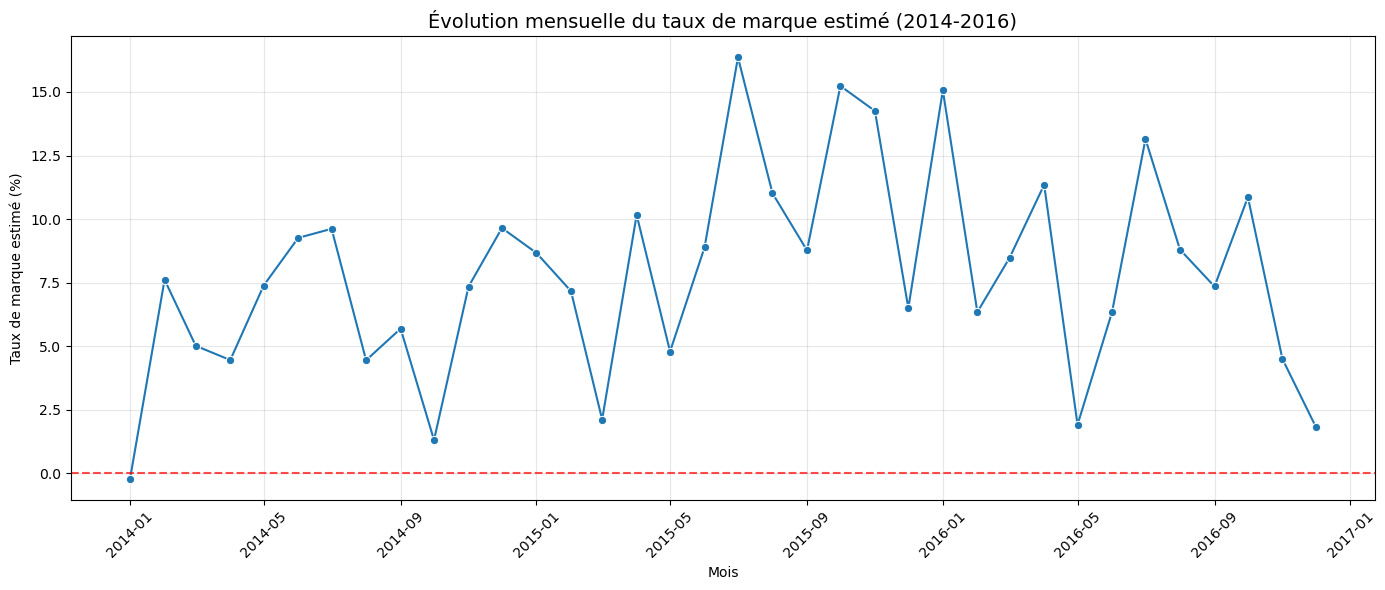

In [124]:
# Définir la taille du graphique
plt.figure(figsize=(14, 6))

# Tracer l'évolution mensuelle du taux de marque
sns.lineplot(
    data=rentabilite_mensuelle,
    x="Month",
    y="Taux_Marque_Estime_%",
    marker="o"
)

# Ajouter une ligne de référence à zéro
plt.axhline(
    y=0,
    linestyle="--",
    color="red",
    alpha=0.7
)

# Personnaliser le graphique
plt.title(
    "Évolution mensuelle du taux de marque estimé (2014-2016)",
    fontsize=14
)
plt.xlabel("Mois")
plt.ylabel("Taux de marque estimé (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## 4. Analyse géographique des ventes

La dimension géographique est directement associée à la table de faits. La jointure ci-dessous est réalisée à partir de `FactInternetSales` et `DimSalesTerritory`, sans dépendre de la table enrichie utilisée dans l'analyse des produits.

In [127]:
# Sélectionner les informations géographiques utiles
territoires_analyse = dim_territory[
    ["SalesTerritoryKey", "Region", "Country", "Group"]
].copy()

# Enrichir les ventes avec les informations géographiques
fact_sales_geo = fact_sales.merge(
    territoires_analyse,
    on="SalesTerritoryKey",
    how="left",
    validate="many_to_one"
)

# Vérifier la conservation des lignes et les correspondances
print("Nombre de lignes avant jointure :", len(fact_sales))
print("Nombre de lignes après jointure :", len(fact_sales_geo))

# Identifier les ventes sans correspondance géographique
ventes_sans_territoire = fact_sales_geo[
    fact_sales_geo["Region"].isna()
]

print(
    "\nNombre de ventes sans correspondance géographique :",
    len(ventes_sans_territoire)
)

print("\nValeurs manquantes dans les informations géographiques :")
display(fact_sales_geo[["Region", "Country", "Group"]].isna().sum())

display(fact_sales_geo.head())

Nombre de lignes avant jointure : 58189
Nombre de lignes après jointure : 58189

Nombre de ventes sans correspondance géographique : 0

Valeurs manquantes dans les informations géographiques :


Region     0
Country    0
Group      0
dtype: int64

,ProductKey,OrderDate,ShipDate,CustomerKey,PromotionKey,SalesTerritoryKey,SalesOrderNumber,SalesOrderLineNumber,OrderQuantity,UnitPrice,TotalProductCost,SalesAmount,TaxAmt,CalculatedTotalCost,StandardCost,Month,Annee,Region,Country,Group
0,310,2014-01-01,2014-01-08,21768,1,6,SO43697,1,2,1789.1350,2171.2942,3578.2700,286.2616,4342.5884,2171.2942,2014-01-01,2014,Canada,Canada,North America
1,346,2014-01-01,2014-01-08,28389,1,7,SO43698,1,2,1699.9950,1912.1544,3399.9900,271.9992,3824.3088,1912.1544,2014-01-01,2014,France,France,Europe
2,346,2014-01-01,2014-01-08,25863,1,1,SO43699,1,2,1699.9950,1912.1544,3399.9900,271.9992,3824.3088,1912.1544,2014-01-01,2014,Northwest,United States,North America
3,336,2014-01-01,2014-01-08,14501,1,4,SO43700,1,2,349.5491,413.1463,699.0982,55.9279,826.2926,413.1463,2014-01-01,2014,Southwest,United States,North America
4,346,2014-01-01,2014-01-08,11003,1,9,SO43701,1,2,1699.9950,1912.1544,3399.9900,271.9992,3824.3088,1912.1544,2014-01-01,2014,Australia,Australia,Pacific


In [128]:
# Agréger les performances commerciales par territoire
performance_territoires = (
    fact_sales_geo
    .groupby(["Group", "Country", "Region"])
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Cout_Total_Estime=("CalculatedTotalCost", "sum"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Quantite_Vendue=("OrderQuantity", "sum"),
        Nombre_Clients=("CustomerKey", "nunique"),
        Nombre_Produits=("ProductKey", "nunique")
    )
    .reset_index()
)

# Calculer les indicateurs de rentabilité
performance_territoires["Benefice_Brut_Estime"] = (
    performance_territoires["Chiffre_Affaires"]
    - performance_territoires["Cout_Total_Estime"]
)

performance_territoires["Taux_Marque_Estime_%"] = (
    performance_territoires["Benefice_Brut_Estime"]
    / performance_territoires["Chiffre_Affaires"] * 100
)

# Classer les territoires par chiffre d'affaires décroissant
performance_territoires = performance_territoires.sort_values(
    "Chiffre_Affaires",
    ascending=False
)

# Afficher les résultats
display(performance_territoires.round(2))

,Group,Country,Region,Chiffre_Affaires,Cout_Total_Estime,Nombre_Commandes,Nombre_Lignes,Quantite_Vendue,Nombre_Clients,Nombre_Produits,Benefice_Brut_Estime,Taux_Marque_Estime_%
9,Pacific,Australia,Australia,9051766.35,8422155.79,6542,12972,20140,3533,158,629610.56,6.96
8,North America,United States,Southwest,5708995.51,5170904.75,5289,11864,18591,4300,158,538090.76,9.43
6,North America,United States,Northwest,3639701.30,3391521.54,3879,8579,13591,3201,157,248179.77,6.82
2,Europe,United Kingdom,United Kingdom,3387490.80,3196601.29,2947,6709,10594,1870,155,190889.51,5.64
1,Europe,Germany,Germany,2890707.51,2658688.82,2412,5460,8424,1710,158,232018.68,8.03
0,Europe,France,France,2640525.76,2394733.08,2411,5382,8442,1741,155,245792.68,9.31
3,North America,Canada,Canada,1966991.16,1821258.99,3170,7142,11414,1537,151,145732.17,7.41
7,North America,United States,Southeast,12124.89,11027.14,14,34,52,10,23,1097.75,9.05
5,North America,United States,Northeast,6532.47,4835.81,10,27,35,8,17,1696.66,25.97
4,North America,United States,Central,3000.83,1753.40,9,20,38,8,15,1247.43,41.57


In [129]:
# Agréger les performances commerciales par pays
performance_pays = (
    fact_sales_geo
    .groupby(["Group", "Country"])
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Cout_Total_Estime=("CalculatedTotalCost", "sum"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Quantite_Vendue=("OrderQuantity", "sum"),
        Nombre_Clients=("CustomerKey", "nunique"),
        Nombre_Produits=("ProductKey", "nunique")
    )
    .reset_index()
)

# Calculer les indicateurs de rentabilité
performance_pays["Benefice_Brut_Estime"] = (
    performance_pays["Chiffre_Affaires"]
    - performance_pays["Cout_Total_Estime"]
)

performance_pays["Taux_Marque_Estime_%"] = (
    performance_pays["Benefice_Brut_Estime"]
    / performance_pays["Chiffre_Affaires"] * 100
)

# Calculer la part de chaque pays dans le chiffre d'affaires global
ca_global = performance_pays["Chiffre_Affaires"].sum()

performance_pays["Part_CA_%"] = (
    performance_pays["Chiffre_Affaires"]
    / ca_global * 100
)

# Classer les pays par chiffre d'affaires décroissant
performance_pays = performance_pays.sort_values(
    "Chiffre_Affaires",
    ascending=False
)

display(performance_pays.round(2))

,Group,Country,Chiffre_Affaires,Cout_Total_Estime,Nombre_Commandes,Nombre_Lignes,Quantite_Vendue,Nombre_Clients,Nombre_Produits,Benefice_Brut_Estime,Taux_Marque_Estime_%,Part_CA_%
4,North America,United States,9370355.00,8580042.64,9201,20524,32307,7527,158,790312.36,8.43,31.97
5,Pacific,Australia,9051766.35,8422155.79,6542,12972,20140,3533,158,629610.56,6.96,30.89
2,Europe,United Kingdom,3387490.80,3196601.29,2947,6709,10594,1870,155,190889.51,5.64,11.56
1,Europe,Germany,2890707.51,2658688.82,2412,5460,8424,1710,158,232018.68,8.03,9.86
0,Europe,France,2640525.76,2394733.08,2411,5382,8442,1741,155,245792.68,9.31,9.01
3,North America,Canada,1966991.16,1821258.99,3170,7142,11414,1537,151,145732.17,7.41,6.71


In [130]:
# Agréger les performances commerciales par groupe géographique
performance_groupes = (
    fact_sales_geo
    .groupby("Group")
    .agg(
        Chiffre_Affaires=("SalesAmount", "sum"),
        Cout_Total_Estime=("CalculatedTotalCost", "sum"),
        Nombre_Commandes=("SalesOrderNumber", "nunique"),
        Nombre_Lignes=("SalesOrderLineNumber", "count"),
        Quantite_Vendue=("OrderQuantity", "sum"),
        Nombre_Clients=("CustomerKey", "nunique"),
        Nombre_Produits=("ProductKey", "nunique"),
        Nombre_Pays=("Country", "nunique")
    )
    .reset_index()
)

# Calculer les indicateurs de rentabilité
performance_groupes["Benefice_Brut_Estime"] = (
    performance_groupes["Chiffre_Affaires"]
    - performance_groupes["Cout_Total_Estime"]
)

performance_groupes["Taux_Marque_Estime_%"] = (
    performance_groupes["Benefice_Brut_Estime"]
    / performance_groupes["Chiffre_Affaires"] * 100
)

# Calculer la contribution au chiffre d'affaires global
performance_groupes["Part_CA_%"] = (
    performance_groupes["Chiffre_Affaires"]
    / fact_sales_geo["SalesAmount"].sum() * 100
)

# Classer les groupes par chiffre d'affaires décroissant
performance_groupes = performance_groupes.sort_values(
    "Chiffre_Affaires",
    ascending=False
)

display(performance_groupes.round(2))

,Group,Chiffre_Affaires,Cout_Total_Estime,Nombre_Commandes,Nombre_Lignes,Quantite_Vendue,Nombre_Clients,Nombre_Produits,Nombre_Pays,Benefice_Brut_Estime,Taux_Marque_Estime_%,Part_CA_%
1,North America,11337346.16,10401301.63,12371,27666,43721,9064,158,2,936044.53,8.26,38.68
2,Pacific,9051766.35,8422155.79,6542,12972,20140,3533,158,1,629610.56,6.96,30.89
0,Europe,8918724.07,8250023.19,7770,17551,27460,5321,158,3,668700.88,7.50,30.43


### Synthèse de l'analyse géographique des ventes

L'analyse géographique met en évidence une concentration du chiffre d'affaires sur deux marchés principaux : les États-Unis et l'Australie, qui représentent ensemble environ 62,86 % du chiffre d'affaires total.

À l'échelle des groupes géographiques, North America arrive en première position avec 38,68 % du chiffre d'affaires et un bénéfice brut estimé de 936 044,53. Europe et Pacific présentent des contributions relativement proches, avec respectivement 30,43 % et 30,89 % du chiffre d'affaires.

Les performances relatives diffèrent toutefois selon les marchés. North America affiche le meilleur taux de marque estimé (8,26 %), suivi d'Europe (7,50 %) et de Pacific (6,96 %).

L'analyse par pays montre également des différences de rentabilité. La France présente le taux de marque estimé le plus élevé (9,31 %), tandis que le Royaume-Uni affiche le plus faible (5,64 %).

Enfin, les trois groupes commercialisent les 158 produits présents dans les ventes. Leur différence de performance ne semble donc pas provenir d'une couverture différente du catalogue, mais doit être étudiée à travers les volumes, les prix de vente et la composition des ventes.

**Limite méthodologique :** les coûts et bénéfices présentés sont estimés à partir des coûts standards. Ils ne représentent pas nécessairement les résultats comptables réels de l'entreprise.

## 5. Limites méthodologiques

- La période de vente observée couvre les années 2014 à 2016. Les comparaisons doivent tenir compte des changements importants de structure des commandes observés en 2016.
- Les bénéfices et taux de rentabilité sont estimés à partir des coûts standards unitaires.
- Les écarts entre territoires décrivent les données disponibles et ne suffisent pas, à eux seuls, à expliquer les causes des différences de performance.